In [20]:
# ===== 0. Local-or-IBM setup (first cell) =====
import warnings
warnings.filterwarnings("ignore")

use_ibm = False
backend = None
sampler = None

try:
    # try to use IBM runtime if available and configured
    from qiskit_ibm_runtime import QiskitRuntimeService, Sampler as IBMSampler
    try:
        service = QiskitRuntimeService()
        backend = service.backend("ibmq_qasm_simulator")
        sampler = IBMSampler(session=service)
        use_ibm = True
        print("Using IBM runtime:", backend.name())
    except Exception:
        use_ibm = False
except Exception:
    use_ibm = False

if not use_ibm:
    # fallback to local Aer
    from qiskit_aer import AerSimulator
    from qiskit_aer.primitives import Sampler as AerSampler
    backend = AerSimulator()
    sampler = AerSampler()
    print("Using local AerSimulator / AerSampler (offline)")


Using local AerSimulator / AerSampler (offline)


In [21]:
# ===== 1. Standard imports =====
import numpy as np
import matplotlib.pyplot as plt
import math
import cplex
from cplex.exceptions import CplexError

from qiskit import QuantumCircuit, transpile, Aer
from qiskit.utils import algorithm_globals
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE
from qiskit.algorithms.optimizers import SPSA
from qiskit.circuit.library import RealAmplitudes
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer


In [22]:
# ===== 2. Problem instance generation =====
class Initializer:
    def __init__(self, n):
        self.n = n

    def generate_instance(self):
        np.random.seed(1543)
        n = self.n
        xc = (np.random.rand(n) - 0.5) * 10
        yc = (np.random.rand(n) - 0.5) * 10
        instance = np.zeros([n, n])
        for ii in range(n):
            for jj in range(ii + 1, n):
                instance[ii, jj] = (xc[ii] - xc[jj]) ** 2 + (yc[ii] - yc[jj]) ** 2
                instance[jj, ii] = instance[ii, jj]
        return xc, yc, instance

# Problem parameters
n = 2  # number of nodes + depot
K = 2  # number of vehicles

initializer = Initializer(n)
xc, yc, instance = initializer.generate_instance()


In [6]:
# Initialize the problem by defining the parameters
n = 2  # number of nodes + depot (n+1)
K = 2  # number of vehicles

In [23]:
# ===== 3. Classical optimizer (CPLEX) =====
class ClassicalOptimizer:
    def __init__(self, instance, n, K):
        self.instance = instance
        self.n = n
        self.K = K

    def compute_allowed_combinations(self):
        f = math.factorial
        return f(self.n) / f(self.K) / f(self.n - self.K)

    def cplex_solution(self):
        instance = self.instance
        n = self.n
        K = self.K

        my_obj = list(instance.reshape(1, n**2)[0]) + [0.0]*(n-1)
        my_ub = [1]*(n**2 + n - 1)
        my_lb = [0]*n**2 + [0.1]*(n-1)
        my_ctype = "I"*n**2 + "C"*(n-1)
        my_rhs = 2*([K] + [1]*(n-1)) + [1 - 0.1 for _ in range((n-1)**2-(n-1))] + [0]*n
        my_sense = "E"*(2*n) + "L"*((n-1)**2-(n-1)) + "E"*n

        try:
            my_prob = cplex.Cplex()
            self.populatebyrow(my_prob, my_obj, my_ub, my_lb, my_ctype, my_sense, my_rhs)
            my_prob.solve()
        except CplexError as exc:
            print(exc)
            return

        x = np.array(my_prob.solution.get_values())
        cost = my_prob.solution.get_objective_value()
        return x, cost

    def populatebyrow(self, prob, my_obj, my_ub, my_lb, my_ctype, my_sense, my_rhs):
        n = self.n
        prob.objective.set_sense(prob.objective.sense.minimize)
        prob.variables.add(obj=my_obj, lb=my_lb, ub=my_ub, types=my_ctype)
        prob.set_log_stream(None)
        prob.set_error_stream(None)
        prob.set_warning_stream(None)
        prob.set_results_stream(None)

        rows = []
        for ii in range(n):
            col = list(range(n*ii, n*(ii+1)))
            coef = [1]*n
            rows.append([col, coef])
        for ii in range(n):
            col = list(range(ii, n**2, n))
            coef = [1]*n
            rows.append([col, coef])

        for ii in range(n):
            for jj in range(n):
                if ii != jj and ii*jj > 0:
                    col = [ii + jj*n, n**2 + ii - 1, n**2 + jj - 1]
                    coef = [1, 1, -1]
                    rows.append([col, coef])

        for ii in range(n):
            col = [ii*(n+1)]
            coef = [1]
            rows.append([col, coef])

        prob.linear_constraints.add(lin_expr=rows, senses=my_sense, rhs=my_rhs)

classical_optimizer = ClassicalOptimizer(instance, n, K)
print("Number of feasible solutions =", classical_optimizer.compute_allowed_combinations())

x = None
z = None
try:
    x, classical_cost = classical_optimizer.cplex_solution()
    z = [x[ii] for ii in range(n**2) if ii//n != ii%n]
    print("Classical solution:", z)
except:
    print("CPLEX may be missing.")


Number of feasible solutions = 1.0
CPLEX may be missing.


In [24]:
# ===== 4. Visualization =====
def visualize_solution(xc, yc, x, C, n, K, title_str):
    plt.figure()
    plt.scatter(xc, yc, s=200)
    for i in range(len(xc)):
        plt.annotate(i, (xc[i]+0.15, yc[i]), size=16, color="r")
    plt.plot(xc[0], yc[0], "r*", ms=20)
    plt.grid()
    for ii in range(0, n**2):
        if x[ii] > 0:
            ix = ii // n
            iy = ii % n
            plt.arrow(xc[ix], yc[ix], xc[iy]-xc[ix], yc[iy]-yc[ix], length_includes_head=True, head_width=0.25)
    plt.title(title_str + " cost = " + str(int(C*100)/100.0))
    plt.show()

if x is not None:
    visualize_solution(xc, yc, x, classical_cost, n, K, "Classical")


Binary cost (no classical verification available): 0
Quantum solution: [1. 1.]
Quantum cost: 3965.0321682066187


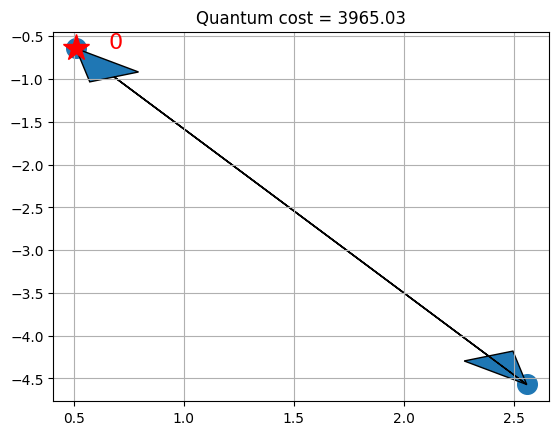

In [25]:
# ===== 5. Quantum optimizer (uses Aer locally if IBM unavailable) =====
class QuantumOptimizer:
    def __init__(self, instance, n, K, backend, sampler):
        self.instance = instance
        self.n = n
        self.K = K
        self.backend = backend
        self.sampler = sampler

    def binary_representation(self, x_sol=None):
        instance = self.instance
        n = self.n
        K = self.K
        A = np.max(instance)*100
        instance_vec = instance.reshape(n**2)
        w_list = [instance_vec[x] for x in range(n**2) if instance_vec[x] > 0]
        w = np.zeros(n*(n-1))
        for ii in range(len(w_list)):
            w[ii] = w_list[ii]

        Id_n = np.eye(n)
        Im_n_1 = np.ones([n-1, n-1])
        Iv_n_1 = np.ones(n)
        Iv_n_1[0] = 0
        Iv_n = np.ones(n-1)
        neg_Iv_n_1 = np.ones(n) - Iv_n_1

        v = np.zeros([n, n*(n-1)])
        for ii in range(n):
            count = ii-1
            for jj in range(n*(n-1)):
                if jj // (n-1) == ii:
                    count = ii
                if jj // (n-1) != ii and jj % (n-1) == count:
                    v[ii][jj] = 1.0

        vn = np.sum(v[1:], axis=0)
        Q = A*(np.kron(Id_n, Im_n_1) + np.dot(v.T, v))
        g = w - 2*A*(np.kron(Iv_n_1,Iv_n) + vn.T) - 2*A*K*(np.kron(neg_Iv_n_1,Iv_n)+v[0].T)
        c = 2*A*(n-1) + 2*A*(K**2)

        if x_sol is not None:
            cost = np.dot(np.around(x_sol), np.dot(Q, np.around(x_sol))) + np.dot(g, np.around(x_sol)) + c
        else:
            cost = 0

        return Q, g, c, cost

    def construct_problem(self, Q, g, c):
        qp = QuadraticProgram()
        for i in range(self.n*(self.n-1)):
            qp.binary_var(str(i))
        qp.objective.quadratic = Q
        qp.objective.linear = g
        qp.objective.constant = c
        return qp

    def solve_problem(self, qp):
        algorithm_globals.random_seed = 10598
        vqe = SamplingVQE(sampler=self.sampler, optimizer=SPSA(), ansatz=RealAmplitudes())
        optimizer = MinimumEigenOptimizer(min_eigen_solver=vqe)
        result = optimizer.solve(qp)
        _, _, _, level = self.binary_representation(x_sol=result.x)
        return result.x, level

quantum_optimizer = QuantumOptimizer(instance, n, K, backend, sampler)

# Verify binary formulation using classical solution if available
try:
    if z is not None:
        Q, g, c, binary_cost = quantum_optimizer.binary_representation(x_sol=z)
        print("Binary cost:", binary_cost, "classical cost:", classical_cost)
        if np.abs(binary_cost-classical_cost) < 0.01:
            print("Binary formulation is correct")
        else:
            print("Warning: Binary formulation may be incorrect")
    else:
        Q, g, c, binary_cost = quantum_optimizer.binary_representation()
        print("Binary cost (no classical verification available):", binary_cost)
except NameError:
    print("Warning: Please run the cells above first.")

qp = quantum_optimizer.construct_problem(Q, g, c)
quantum_solution, quantum_cost = quantum_optimizer.solve_problem(qp)
print("Quantum solution:", quantum_solution)
print("Quantum cost:", quantum_cost)

# Put the solution in full matrix form for visualization
x_quantum = np.zeros(n**2)
kk = 0
for ii in range(n**2):
    if ii//n != ii%n:
        x_quantum[ii] = quantum_solution[kk]
        kk += 1

# visualize quantum solution
visualize_solution(xc, yc, x_quantum, quantum_cost, n, K, "Quantum")

# visualize classical solution again for comparison
if x is not None:
    visualize_solution(xc, yc, x, classical_cost, n, K, "Classical")
